# Workshop 7: LSTM time-series forecasting

**Real-life problem:** Forecasting tomorrow's temperature in London. It has the same shape as energy, sales or footfall forecasting.

**My twist:** Forecast **London's** temperature instead of Jena's: 16 years of hourly weather (2010-2025) from the free Open-Meteo archive, saved as `london_hourly_2010_2025.csv.gz`. Predict the next 24 hours from the last 72, and compare four forecasts: 'same as now', 'same time yesterday', a plain linear regression, and the lecturer's LSTM.

**Done when:** MAE for naive vs LSTM at 1 h, 6 h and 24 h ahead, and an honest verdict on where the LSTM isn't worth it.

*Baseline = the lecturer's workshop code (unmodified copy in `_baseline/`). Everything below the line starts as that baseline; edit it.*

---


## Part A: time-series forecasting with LSTMs (the lecturer's baseline)

TensorFlow's forecasting tutorial on the Jena (Germany) climate data: a univariate LSTM, then a multivariate model that predicts one value and one that predicts 72. Two small fixes so it runs on current TensorFlow: Keras 3 now returns the *folder* a zip was extracted to (so the CSV path is built from it), and warnings are silenced because they print file paths from your computer. Everything else is unchanged; it takes about 4 minutes.

# Time series forecasting

This workshop is an introduction to time series forecasting using Recurrent Neural Networks (RNNs). This is covered in two parts: first, you will forecast a univariate time series, then you will forecast a multivariate time series.

In [ ]:
import os, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'     # hide TensorFlow start-up messages
warnings.filterwarnings('ignore')            # Keras 3 warnings print file paths from your computer

from __future__ import absolute_import, division, print_function, unicode_literals
import tensorflow as tf
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

mpl.rcParams['figure.figsize'] = (8, 6)
mpl.rcParams['axes.grid'] = False

## The weather dataset
This tutorial uses a [weather time series dataset](https://www.bgc-jena.mpg.de/wetter/) recorded by the [Max-Planck-Institute for Biogeochemistry](https://www.bgc-jena.mpg.de/index.php/Main/HomePage).

This dataset contains 14 different features such as air temperature, atmospheric pressure, and humidity. These were collected every 10 minutes, beginning in 2003. For efficiency, you will use only the data collected between 2009 and 2016. This section of the dataset was prepared by François Chollet for his book [Deep Learning with Python](https://www.manning.com/books/deep-learning-with-python).

In [ ]:
zip_path = tf.keras.utils.get_file(
    origin='https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip',
    fname='jena_climate_2009_2016.csv.zip',
    extract=True)
# Keras 3 returns the folder it extracted to (older versions returned the zip path)
csv_path = os.path.join(zip_path, 'jena_climate_2009_2016.csv') if os.path.isdir(zip_path) else os.path.splitext(zip_path)[0]

In [ ]:
df = pd.read_csv(csv_path)

Let's take a glance at the data.

In [ ]:
df.head()

,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


As you can see above, an observation is recorded every 10 mintues. This means that, for a single hour, you will have 6 observations. Similarly, a single day will contain 144 (6x24) observations. 

Given a specific time, let's say you want to predict the temperature 6 hours in the future. In order to make this prediction, you choose to use 5 days of observations. Thus, you would create a window containing the last 720(5x144) observations to train the model. Many such configurations are possible, making this dataset a good one to experiment with.

The function below returns the above described windows of time for the model to train on. The parameter `history_size` is the size of the past window of information. The `target_size` is how far in the future does the model need to learn to predict. The `target_size` is the label that needs to be predicted.

In [ ]:
def univariate_data(dataset, start_index, end_index, history_size, target_size):
  data = []
  labels = []

  start_index = start_index + history_size
  if end_index is None:
    end_index = len(dataset) - target_size

  for i in range(start_index, end_index):
    indices = range(i-history_size, i)
    # Reshape data from (history_size,) to (history_size, 1)
    data.append(np.reshape(dataset[indices], (history_size, 1)))
    labels.append(dataset[i+target_size])
  return np.array(data), np.array(labels)

In both the following tutorials, the first 300,000 rows of the data will be the training dataset, and there remaining will be the validation dataset. This amounts to ~2100 days worth of training data.

In [ ]:
TRAIN_SPLIT = 300000

Setting seed to ensure reproducibility.

In [ ]:
tf.random.set_seed(13)

## Part 1: Forecast a univariate time series
First, you will train a model using only a single feature (temperature), and use it to make predictions for that value in the future.

Let's first extract only the temperature from the dataset.

In [ ]:
uni_data = df['T (degC)']
uni_data.index = df['Date Time']
uni_data.head()

Date Time
01.01.2009 00:10:00   -8.02
01.01.2009 00:20:00   -8.41
01.01.2009 00:30:00   -8.51
01.01.2009 00:40:00   -8.31
01.01.2009 00:50:00   -8.27
Name: T (degC), dtype: float64

Let's observe how this data looks across time.

array([<Axes: xlabel='Date Time'>], dtype=object)

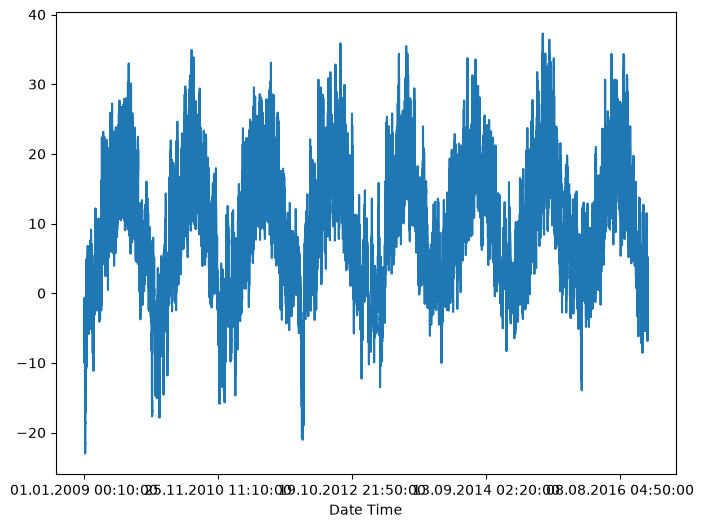

In [ ]:
uni_data.plot(subplots=True)

In [ ]:
uni_data = uni_data.values

It is important to scale features before training a neural network. Standardization is a common way of doing this scaling by subtracting the mean and dividing by the standard deviation of each feature.You could also use a `tf.keras.utils.normalize` method that rescales the values into a range of [0,1].

Note: The mean and standard deviation should only be computed using the training data.

In [ ]:
uni_train_mean = uni_data[:TRAIN_SPLIT].mean()
uni_train_std = uni_data[:TRAIN_SPLIT].std()

Let's standardize the data.

In [ ]:
uni_data = (uni_data-uni_train_mean)/uni_train_std

Let's now create the data for the univariate model. For part 1, the model will be given the last 20 recorded temperature observations, and needs to learn to predict the temperature at the next time step. 

In [ ]:
univariate_past_history = 20
univariate_future_target = 0

x_train_uni, y_train_uni = univariate_data(uni_data, 0, TRAIN_SPLIT,
                                           univariate_past_history,
                                           univariate_future_target)
x_val_uni, y_val_uni = univariate_data(uni_data, TRAIN_SPLIT, None,
                                       univariate_past_history,
                                       univariate_future_target)

This is what the `univariate_data` function returns.

In [ ]:
print ('Single window of past history')
print (x_train_uni[1])
print ('\n Target temperature to predict')
print (y_train_uni[1])

Single window of past history
[[-2.04281897]
 [-2.05439744]
 [-2.0312405 ]
 [-2.02660912]
 [-2.00113649]
 [-1.95134907]
 [-1.95134907]
 [-1.98492663]
 [-2.04513467]
 [-2.08334362]
 [-2.09723778]
 [-2.09376424]
 [-2.09144854]
 [-2.07176515]
 [-2.07176515]
 [-2.07639653]
 [-2.08913285]
 [-2.09260639]
 [-2.10418486]
 [-2.10418486]]

 Target temperature to predict
-2.0949220845536356


Now that the data has been created, let's take a look at a single example. The information given to the network is given in blue, and it must predict the value at the red cross.

In [ ]:
def create_time_steps(length):
  return list(range(-length, 0))

In [ ]:
def show_plot(plot_data, delta, title):
  labels = ['History', 'True Future', 'Model Prediction']
  marker = ['.-', 'rx', 'go']
  time_steps = create_time_steps(plot_data[0].shape[0])
  if delta:
    future = delta
  else:
    future = 0

  plt.title(title)
  for i, x in enumerate(plot_data):
    if i:
      plt.plot(future, plot_data[i], marker[i], markersize=10,
               label=labels[i])
    else:
      plt.plot(time_steps, plot_data[i].flatten(), marker[i], label=labels[i])
  plt.legend()
  plt.xlim([time_steps[0], (future+5)*2])
  plt.xlabel('Time-Step')
  return plt

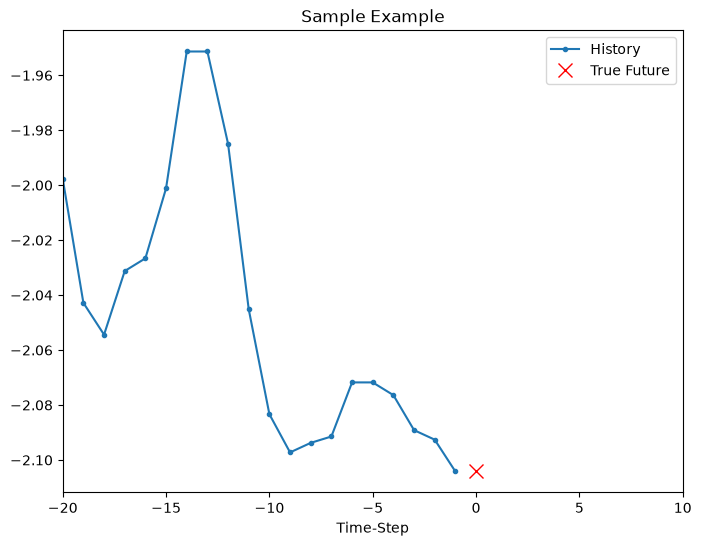

In [ ]:
show_plot([x_train_uni[0], y_train_uni[0]], 0, 'Sample Example');

### Baseline
Before proceeding to train a model, let's first set a simple baseline. Given an input point, the baseline method looks at all the history and predicts the next point to be the average of the last 20 observations.

In [ ]:
def baseline(history):
  return np.mean(history)

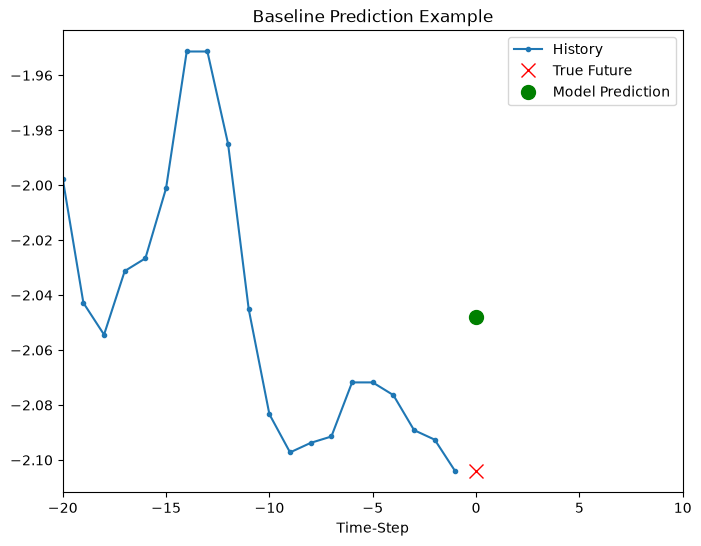

In [ ]:
show_plot([x_train_uni[0], y_train_uni[0], baseline(x_train_uni[0])], 0,
           'Baseline Prediction Example');

Let's see if you can beat this baseline using a recurrent neural network.

### Recurrent neural network

A Recurrent Neural Network (RNN) is a type of neural network well-suited to time series data. RNNs process a time series step-by-step, maintaining an internal state summarizing the information they've seen so far. 
Let's now use `tf.data` to shuffle, batch, and cache the dataset.

In [ ]:
BATCH_SIZE = 256
BUFFER_SIZE = 10000

train_univariate = tf.data.Dataset.from_tensor_slices((x_train_uni, y_train_uni))
train_univariate = train_univariate.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat()

val_univariate = tf.data.Dataset.from_tensor_slices((x_val_uni, y_val_uni))
val_univariate = val_univariate.batch(BATCH_SIZE).repeat()

The following visualisation should help you understand how the data is represented after batching.

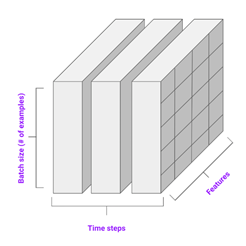

You will see the LSTM requires the input shape of the data it is being given.

In [ ]:
x_train_uni.shape

(299980, 20, 1)

In [ ]:
x_train_uni.shape[-2:]

(20, 1)

In [ ]:
simple_lstm_model = tf.keras.models.Sequential([
    tf.keras.layers.LSTM(8, input_shape=x_train_uni.shape[-2:]),
    tf.keras.layers.Dense(1)
])

simple_lstm_model.compile(optimizer='adam', loss='mae')

In [ ]:
for x, y in val_univariate.take(1):
    print(simple_lstm_model.predict(x).shape)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
(256, 1)


Let's train the model now. Due to the large size of the dataset, in the interest of saving time, each epoch will only run for 200 steps, instead of the complete training data as normally done.

In [ ]:
EVALUATION_INTERVAL = 200
EPOCHS = 10

simple_lstm_model.fit(train_univariate, epochs=EPOCHS,
                      steps_per_epoch=EVALUATION_INTERVAL,
                      validation_data=val_univariate, validation_steps=50)

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7850 - val_loss: 0.1518
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1346 - val_loss: 0.0354
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0465 - val_loss: 0.0290
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0434 - val_loss: 0.0250
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0271 - val_loss: 0.0219
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0290 - val_loss: 0.0201
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0263 - val_loss: 0.0190
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0246 - val_loss: 0.0179
Epoch 9/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0239 - val_loss: 0.0173
Epoch 10/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0217 - val_loss: 0.0163


#### Predict using the simple LSTM model
Now that you have trained your simple LSTM, let's try and make a few predictions.

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


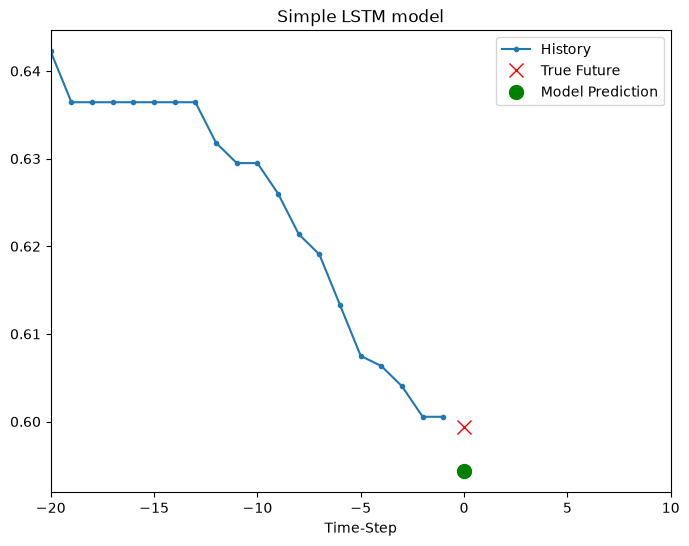

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


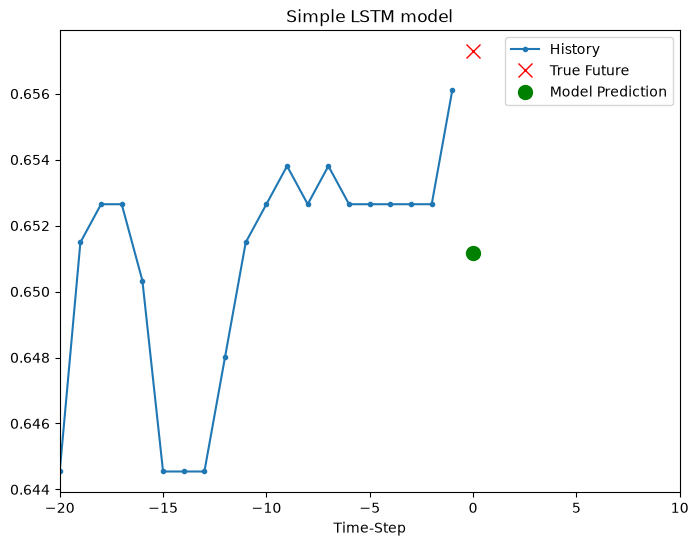

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


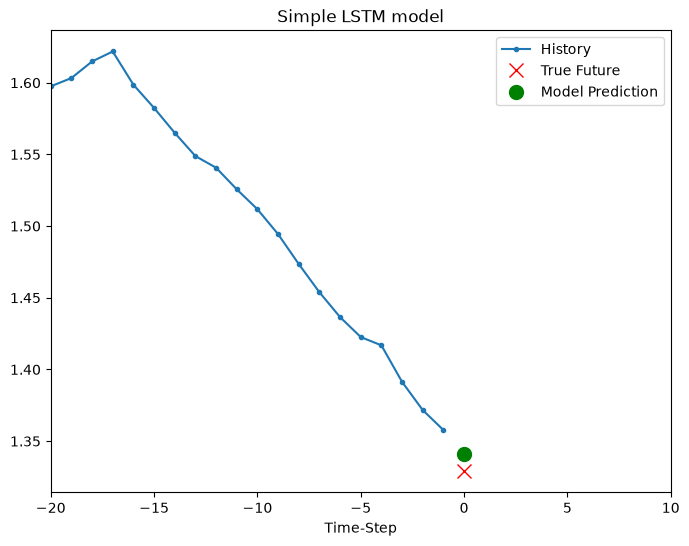

In [ ]:
for x, y in val_univariate.take(3):
  plot = show_plot([x[0].numpy(), y[0].numpy(),
                    simple_lstm_model.predict(x)[0]], 0, 'Simple LSTM model')
  plot.show()

This looks better than the baseline. Now that you have seen the basics, let's move on to part two, where you will work with a multivariate time series.

## Part 2: Forecast a multivariate time series

The original dataset contains fourteen features. For simplicity, this section considers only three of the original fourteen. The features used are air temperature, atmospheric pressure, and air density. 

To use more features, add their names to this list.

In [ ]:
features_considered = ['p (mbar)', 'T (degC)', 'rho (g/m**3)']

In [ ]:
features = df[features_considered]
features.index = df['Date Time']
features.head()

,p (mbar),T (degC),rho (g/m**3)
Date Time,,,
01.01.2009 00:10:00,996.52,-8.02,1307.75
01.01.2009 00:20:00,996.57,-8.41,1309.80
01.01.2009 00:30:00,996.53,-8.51,1310.24
01.01.2009 00:40:00,996.51,-8.31,1309.19
01.01.2009 00:50:00,996.51,-8.27,1309.00


Let's have a look at how each of these features vary across time.

array([<Axes: xlabel='Date Time'>, <Axes: xlabel='Date Time'>,
       <Axes: xlabel='Date Time'>], dtype=object)

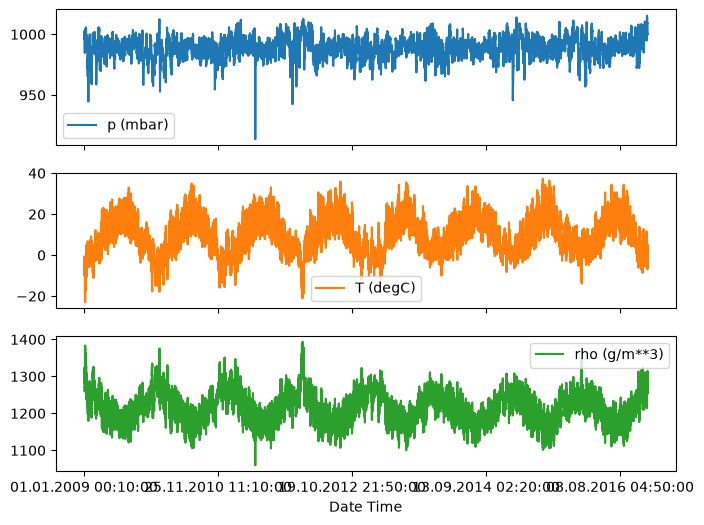

In [ ]:
features.plot(subplots=True)

As mentioned, the first step will be to standardize the dataset using the mean and standard deviation of the training data.

In [ ]:
dataset = features.values
data_mean = dataset[:TRAIN_SPLIT].mean(axis=0)
data_std = dataset[:TRAIN_SPLIT].std(axis=0)

In [ ]:
dataset = (dataset-data_mean)/data_std

In [ ]:
dataset.shape

(420551, 3)

### Single step model
In a single step setup, the model learns to predict a single point in the future based on some history provided.

The below function performs the same windowing task as above, however, here it samples the past observation based on the step size given.

In [ ]:
def multivariate_data(dataset, target, start_index, end_index, history_size,
                      target_size, step, single_step=False):
  data = []
  labels = []

  start_index = start_index + history_size
  if end_index is None:
    end_index = len(dataset) - target_size

  for i in range(start_index, end_index):
    indices = range(i-history_size, i, step)
    data.append(dataset[indices])

    if single_step:
      labels.append(target[i+target_size])
    else:
      labels.append(target[i:i+target_size])

  return np.array(data), np.array(labels)

In this tutorial, the network is shown data from the last five (5) days, i.e. 720 observations that are sampled every 10 mins. The sampling is done every one hour since a drastic change is not expected within 60 minutes. Thus, 120 observation represent history of the last five days.  For the single step prediction model, the label for a datapoint is the temperature 12 hours into the future. In order to create a label for this, the temperature after 72(12*6) observations is used.

In [ ]:
past_history = 720
future_target = 72
STEP = 6

x_train_single, y_train_single = multivariate_data(dataset, dataset[:, 1], 0,
                                                   TRAIN_SPLIT, past_history,
                                                   future_target, STEP,
                                                   single_step=True)
x_val_single, y_val_single = multivariate_data(dataset, dataset[:, 1],
                                               TRAIN_SPLIT, None, past_history,
                                               future_target, STEP,
                                               single_step=True)

Let's look at a single data-point.


In [ ]:
print ('Single window of past history : {}'.format(x_train_single[0].shape))

Single window of past history : (120, 3)


In [ ]:
train_data_single = tf.data.Dataset.from_tensor_slices((x_train_single, y_train_single))
train_data_single = train_data_single.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat()

val_data_single = tf.data.Dataset.from_tensor_slices((x_val_single, y_val_single))
val_data_single = val_data_single.batch(BATCH_SIZE).repeat()

In [ ]:
single_step_model = tf.keras.models.Sequential()
single_step_model.add(tf.keras.layers.LSTM(32,
                                           input_shape=x_train_single.shape[-2:]))
single_step_model.add(tf.keras.layers.Dense(1))

single_step_model.compile(optimizer=tf.keras.optimizers.RMSprop(), loss='mae')

Let's check out a sample prediction.

In [ ]:
for x, y in val_data_single.take(1):
  print(single_step_model.predict(x).shape)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
(256, 1)


In [ ]:
single_step_history = single_step_model.fit(train_data_single, epochs=EPOCHS,
                                            steps_per_epoch=EVALUATION_INTERVAL,
                                            validation_data=val_data_single,
                                            validation_steps=50)

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 0.3171 - val_loss: 0.2584
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 0.2636 - val_loss: 0.2444
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 0.2634 - val_loss: 0.2487
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 0.2601 - val_loss: 0.2443
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - loss: 0.2297 - val_loss: 0.2359
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 38ms/step - loss: 0.2417 - val_loss: 0.2602
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 0.2447 - val_loss: 0.2670
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 0.2438 - val_loss: 0.2632
Epoch 9/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 0.2470 - val_loss: 0.2475
Epoch 10/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - loss: 0.2430 - val_loss: 0.2342


In [ ]:
def plot_train_history(history, title):
  loss = history.history['loss']
  val_loss = history.history['val_loss']

  epochs = range(len(loss))

  plt.figure()

  plt.plot(epochs, loss, 'b', label='Training loss')
  plt.plot(epochs, val_loss, 'r', label='Validation loss')
  plt.title(title)
  plt.legend()

  plt.show()

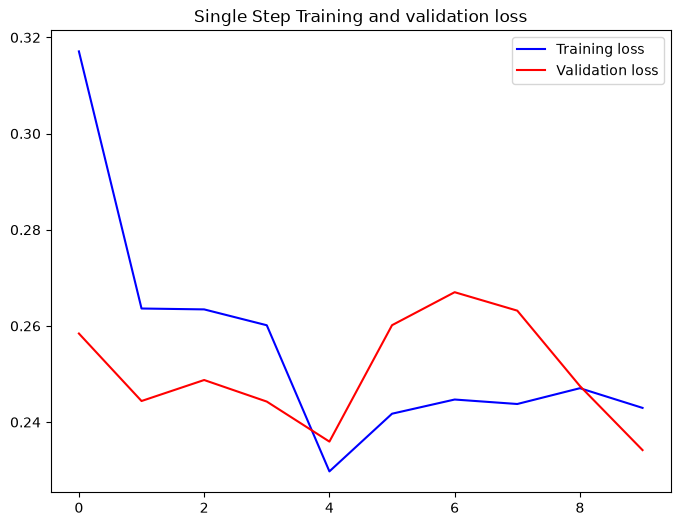

In [ ]:
plot_train_history(single_step_history,
                   'Single Step Training and validation loss')

#### Predict a single step future
Now that the model is trained, let's make a few sample predictions. The model is given the history of three features over the past five days sampled every hour (120 data-points), since the goal is to predict the temperature, the plot only displays the past temperature. The prediction is made one day into the future (hence the gap between the history and prediction). 

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


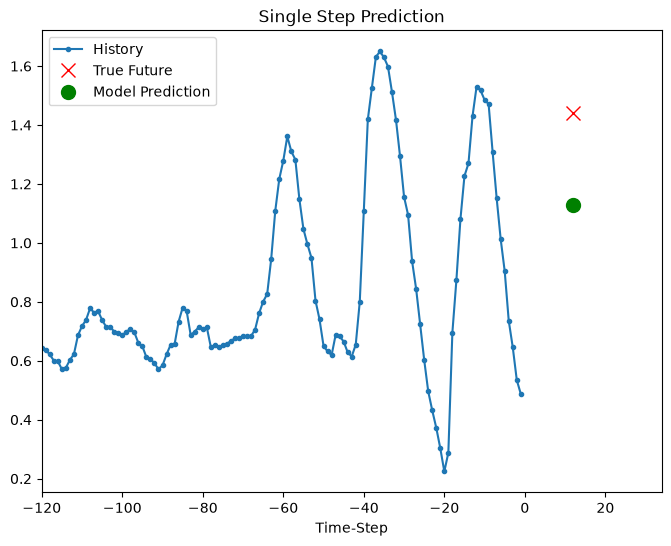

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


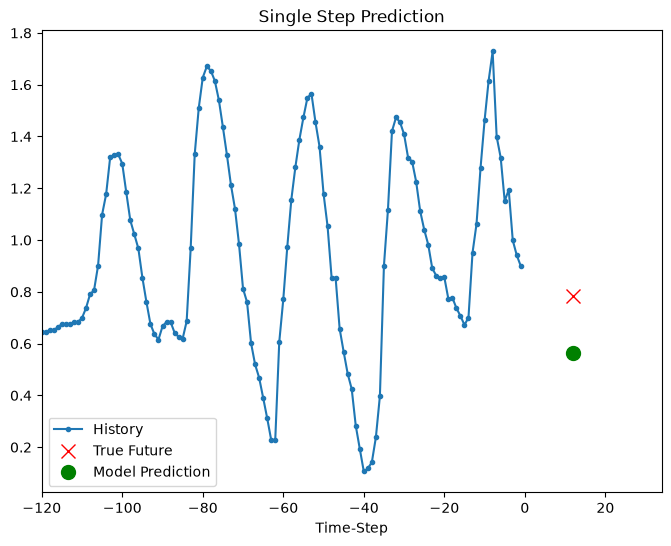

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


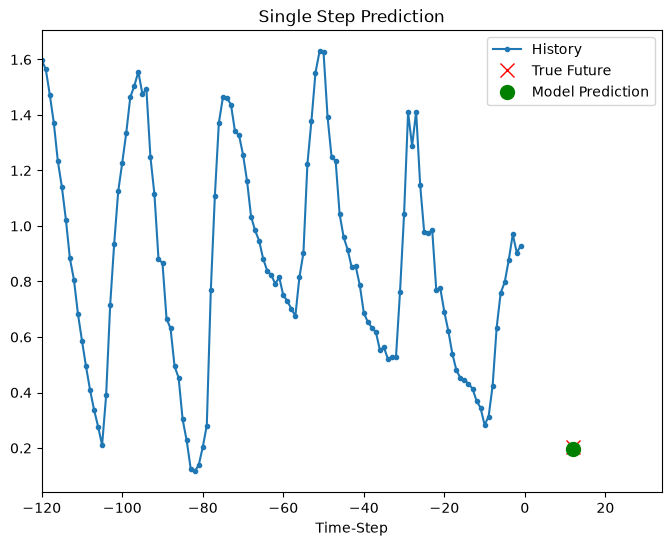

In [ ]:
for x, y in val_data_single.take(3):
  plot = show_plot([x[0][:, 1].numpy(), y[0].numpy(),
                    single_step_model.predict(x)[0]], 12,
                   'Single Step Prediction')
  plot.show()

### Multi-Step model
In a multi-step prediction model, given a past history, the model needs to learn to predict a range of future values. Thus, unlike a single step model, where only a single future point is predicted, a multi-step model predict a sequence of the future.

For the multi-step model, the training data again consists of recordings over the past five days sampled every hour. However, here, the model needs to learn to predict the temperature for the next 12 hours. Since an obversation is taken every 10 minutes, the output is 72 predictions. For this task, the dataset needs to be prepared accordingly, thus the first step is just to create it again, but with a different target window.

In [ ]:
future_target = 72
x_train_multi, y_train_multi = multivariate_data(dataset, dataset[:, 1], 0,
                                                 TRAIN_SPLIT, past_history,
                                                 future_target, STEP)
x_val_multi, y_val_multi = multivariate_data(dataset, dataset[:, 1],
                                             TRAIN_SPLIT, None, past_history,
                                             future_target, STEP)

Let's check out a sample data-point.

In [ ]:
print ('Single window of past history : {}'.format(x_train_multi[0].shape))
print ('\n Target temperature to predict : {}'.format(y_train_multi[0].shape))

Single window of past history : (120, 3)

 Target temperature to predict : (72,)


In [ ]:
train_data_multi = tf.data.Dataset.from_tensor_slices((x_train_multi, y_train_multi))
train_data_multi = train_data_multi.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat()

val_data_multi = tf.data.Dataset.from_tensor_slices((x_val_multi, y_val_multi))
val_data_multi = val_data_multi.batch(BATCH_SIZE).repeat()

Plotting a sample data-point.

In [ ]:
def multi_step_plot(history, true_future, prediction):
  plt.figure(figsize=(12, 6))
  num_in = create_time_steps(len(history))
  num_out = len(true_future)

  plt.plot(num_in, np.array(history[:, 1]), label='History')
  plt.plot(np.arange(num_out)/STEP, np.array(true_future), 'bo',
           label='True Future')
  if prediction.any():
    plt.plot(np.arange(num_out)/STEP, np.array(prediction), 'ro',
             label='Predicted Future')
  plt.legend(loc='upper left')
  plt.show()

In this plot and subsequent similar plots, the history and the future data are sampled every hour.

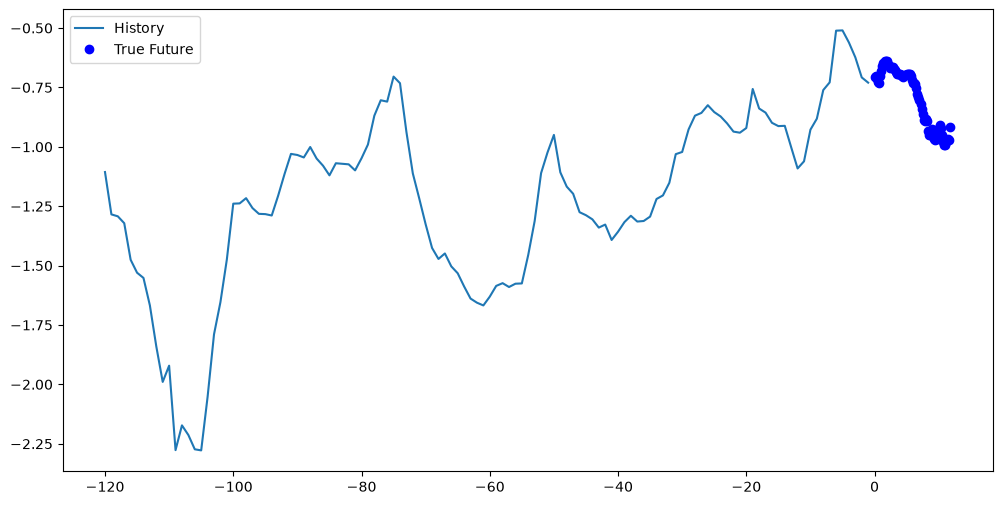

In [ ]:
for x, y in train_data_multi.take(1):
  multi_step_plot(x[0], y[0], np.array([0]))

Since the task here is a bit more complicated than the previous task, the model now consists of two LSTM layers. Finally, since 72 predictions are made, the dense layer outputs 72 predictions.

In [ ]:
multi_step_model = tf.keras.models.Sequential()
multi_step_model.add(tf.keras.layers.LSTM(32,
                                          return_sequences=True,
                                          input_shape=x_train_multi.shape[-2:]))
multi_step_model.add(tf.keras.layers.LSTM(16, activation='relu'))
multi_step_model.add(tf.keras.layers.Dense(72))

multi_step_model.compile(optimizer=tf.keras.optimizers.RMSprop(clipvalue=1.0), loss='mae')

Let's see how the model predicts before it trains.

In [ ]:
for x, y in val_data_multi.take(1):
  print (multi_step_model.predict(x).shape)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step  
(256, 72)


In [ ]:
multi_step_history = multi_step_model.fit(train_data_multi, epochs=EPOCHS,
                                          steps_per_epoch=EVALUATION_INTERVAL,
                                          validation_data=val_data_multi,
                                          validation_steps=50)

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 16s 75ms/step - loss: 1.5955 - val_loss: 0.3235
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 14s 69ms/step - loss: 0.3467 - val_loss: 0.2639
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 67ms/step - loss: 0.2896 - val_loss: 0.2280
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 14s 69ms/step - loss: 0.2345 - val_loss: 0.2128
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - loss: 0.1993 - val_loss: 0.1995
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 14s 68ms/step - loss: 0.2091 - val_loss: 0.2144
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 65ms/step - loss: 0.2014 - val_loss: 0.2111
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - loss: 0.1987 - val_loss: 0.1919
Epoch 9/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 66ms/step - loss: 0.2003 - val_loss: 0.1820
Epoch 10/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 67ms/step - loss: 0.1910 - val_loss: 0.1868


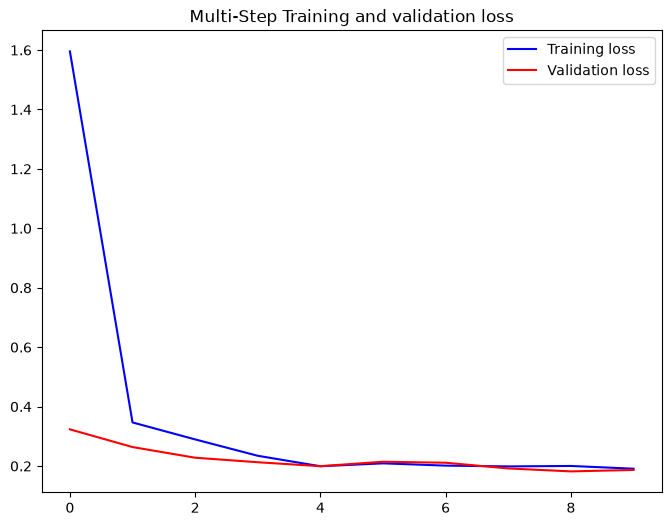

In [ ]:
plot_train_history(multi_step_history, 'Multi-Step Training and validation loss')

#### Predict a multi-step future
Let's now have a look at how well your network has learnt to predict the future.

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


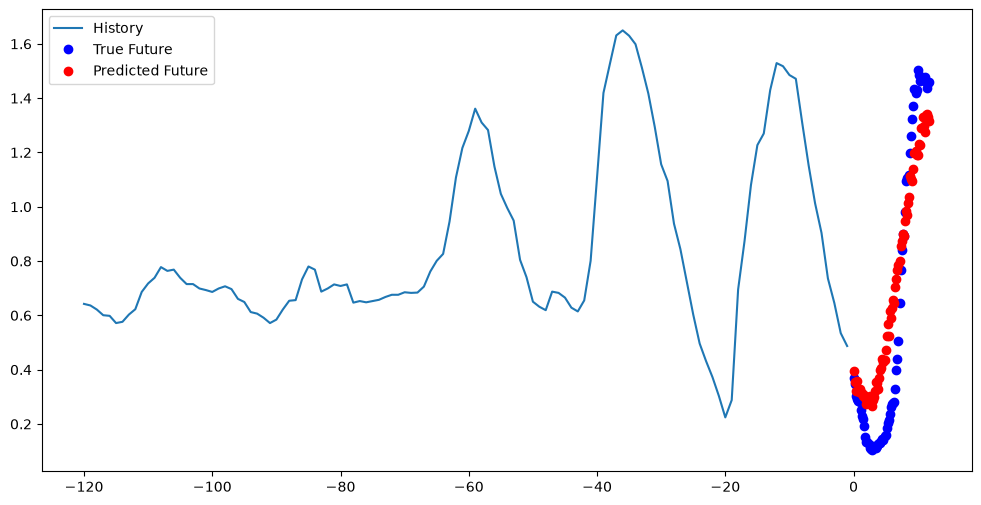

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


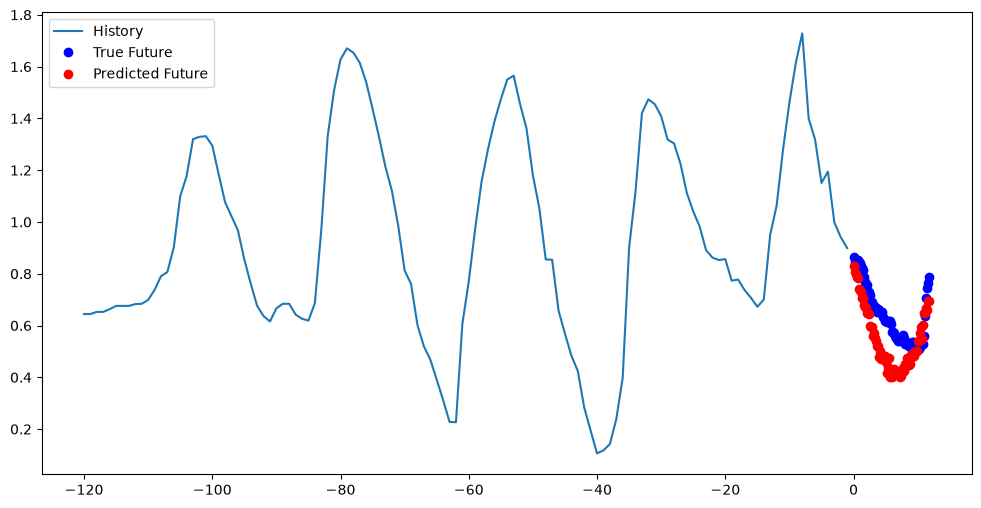

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


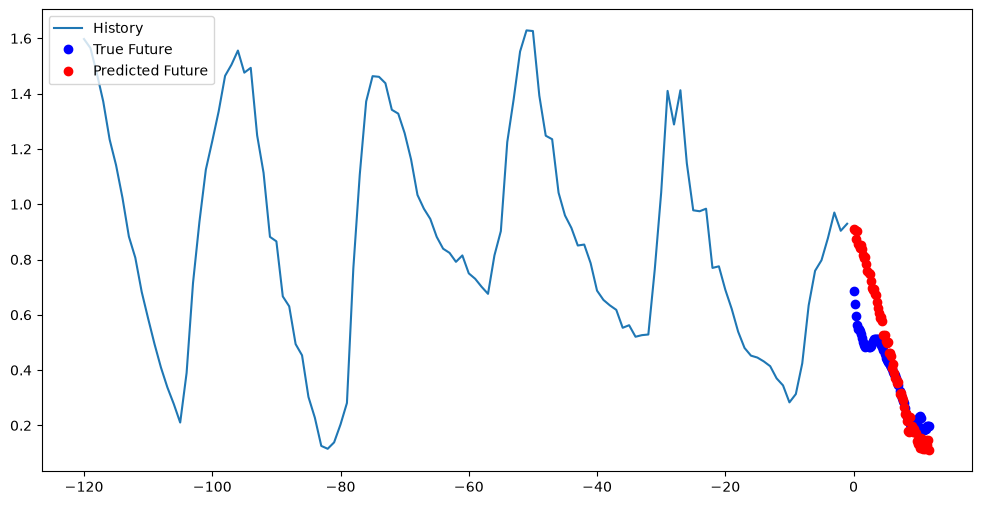

In [ ]:
for x, y in val_data_multi.take(3):
  multi_step_plot(x[0], y[0], multi_step_model.predict(x)[0])

---
## Part B: real life: how well can London's temperature be forecast from its own past?

**Question:** a heating engineer, an event planner or an energy trader wants tomorrow's temperature. **How good is a forecast that only looks at London's recent weather, and is an LSTM worth it over simple alternatives?**

**Data:** hourly temperature, humidity, surface pressure and wind speed for central London, 2010 to 2025 (140,256 hours), from the [Open-Meteo](https://open-meteo.com) historical weather archive (CC BY 4.0). It is *modelled* weather for a grid cell around 10 km wide, not one weather station, so extremes are smoothed: its hottest hour is 37.9 °C, while stations reached about 40 °C in the July 2022 heatwave.

**Set-up:** use the **last 72 hours** to predict the **next 24**. Split by time, never shuffled: train on 2010-2021, tune on 2022-2023, and test on **2024-2025**, years no model has seen. Errors are mean absolute errors in °C.

**Four forecasts:**
1. **Same as now:** the temperature stays where it is.
2. **Same time yesterday:** each hour copies the same hour the day before.
3. **Linear regression:** a weighted sum of the last 72 hours of all four measurements.
4. **LSTM:** the lecturer's design (LSTM with 32 units, mean-absolute-error loss), predicting all 24 hours at once, trained for up to 30 epochs with early stopping.

In [ ]:
import os, warnings, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.linear_model import Ridge
tf.get_logger().setLevel('ERROR')

london = pd.read_csv('london_hourly_2010_2025.csv.gz', parse_dates=['time_utc'])
FEATURES = ['temp_c', 'humidity_pct', 'pressure_hpa', 'wind_kmh']
print(f'{len(london):,} hours, {london.time_utc.min():%Y-%m-%d} to {london.time_utc.max():%Y-%m-%d}; missing values: {london.isna().sum().sum()}')

PAST, AHEAD = 72, 24
X = london[FEATURES].to_numpy('float32'); temp = london['temp_c'].to_numpy('float32'); year = london['time_utc'].dt.year.to_numpy()
train_rows = year <= 2021
X_norm = (X - X[train_rows].mean(axis=0)) / X[train_rows].std(axis=0)           # scaled with training years only

n = len(temp) - PAST - AHEAD + 1                                                   # number of complete (past, future) windows
windows = sliding_window_view(X_norm, (PAST, len(FEATURES)))[:, 0][:n]           # (n, 72, 4): the past 72 hours
future = sliding_window_view(temp, AHEAD)[PAST:PAST + n]                          # (n, 24): the next 24 hours of temperature
past_temp = sliding_window_view(temp, PAST)[:n]                                   # (n, 72): raw past temperature, for the simple forecasts
end_year = year[PAST - 1:PAST - 1 + n]                                            # year of the last hour each window has seen
train, val, test = end_year <= 2021, (end_year >= 2022) & (end_year <= 2023), end_year >= 2024
print(f'windows: train {train.sum():,} | tune {val.sum():,} | test {test.sum():,}')

140,256 hours, 2010-01-01 to 2025-12-31; missing values: 0
windows: train 105,121 | tune 17,520 | test 17,520


In [ ]:
hours = np.arange(1, AHEAD + 1)
def mae_by_hour(pred):
    return np.abs(pred - future[test]).mean(axis=0)                               # average error at each hour ahead (°C)

errors, seconds = {}, {}
errors['same as now'] = mae_by_hour(np.repeat(past_temp[test][:, -1:], AHEAD, axis=1))
errors['same time yesterday'] = mae_by_hour(past_temp[test][:, PAST - 24 + hours - 1])

t0 = time.time()
linreg = Ridge(alpha=1.0).fit(windows[train].reshape(train.sum(), -1), future[train])
errors['linear regression'] = mae_by_hour(linreg.predict(windows[test].reshape(test.sum(), -1)))
seconds['linear regression'] = time.time() - t0

In [ ]:
keras.utils.set_random_seed(0)
lstm = keras.Sequential([keras.Input(shape=(PAST, len(FEATURES))), layers.LSTM(32), layers.Dense(AHEAD)])
lstm.compile(optimizer='adam', loss='mae')
t0 = time.time()
history = lstm.fit(windows[train], future[train], validation_data=(windows[val], future[val]), batch_size=256, epochs=30, verbose=2,
                   callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
errors['LSTM'] = mae_by_hour(lstm.predict(windows[test], verbose=0))
seconds['LSTM'] = time.time() - t0
print(f'LSTM: {len(history.history["loss"])} epochs in {seconds["LSTM"]:.0f} s; linear regression: {seconds["linear regression"]:.1f} s')

Epoch 1/30
411/411 - 11s - 27ms/step - loss: 5.9315 - val_loss: 3.5810
Epoch 2/30
411/411 - 10s - 25ms/step - loss: 2.6262 - val_loss: 2.7061
Epoch 3/30
411/411 - 10s - 24ms/step - loss: 2.2238 - val_loss: 2.2360
Epoch 4/30
411/411 - 10s - 24ms/step - loss: 1.8142 - val_loss: 1.8973
Epoch 5/30
411/411 - 10s - 24ms/step - loss: 1.6438 - val_loss: 1.7652
Epoch 6/30
411/411 - 9s - 23ms/step - loss: 1.5786 - val_loss: 1.7023
Epoch 7/30
411/411 - 9s - 22ms/step - loss: 1.5416 - val_loss: 1.6648
Epoch 8/30
411/411 - 9s - 22ms/step - loss: 1.5155 - val_loss: 1.6382
Epoch 9/30
411/411 - 9s - 21ms/step - loss: 1.4960 - val_loss: 1.6186
Epoch 10/30
411/411 - 9s - 22ms/step - loss: 1.4808 - val_loss: 1.6040
Epoch 11/30
411/411 - 9s - 22ms/step - loss: 1.4682 - val_loss: 1.5916
Epoch 12/30
411/411 - 9s - 22ms/step - loss: 1.4570 - val_loss: 1.5810
Epoch 13/30
411/411 - 9s - 22ms/step - loss: 1.4470 - val_loss: 1.5722
Epoch 14/30
411/411 - 9s - 22ms/step - loss: 1.4378 - val_loss: 1.5657
Epoch 15/3

### 1. How good is each forecast?

,1 h ahead,3 h ahead,6 h ahead,12 h ahead,24 h ahead
same as now,0.61,1.61,2.81,3.93,2.11
same time yesterday,2.11,2.11,2.11,2.11,2.11
linear regression,0.34,0.81,1.25,1.64,1.96
LSTM,0.41,0.81,1.21,1.58,1.87


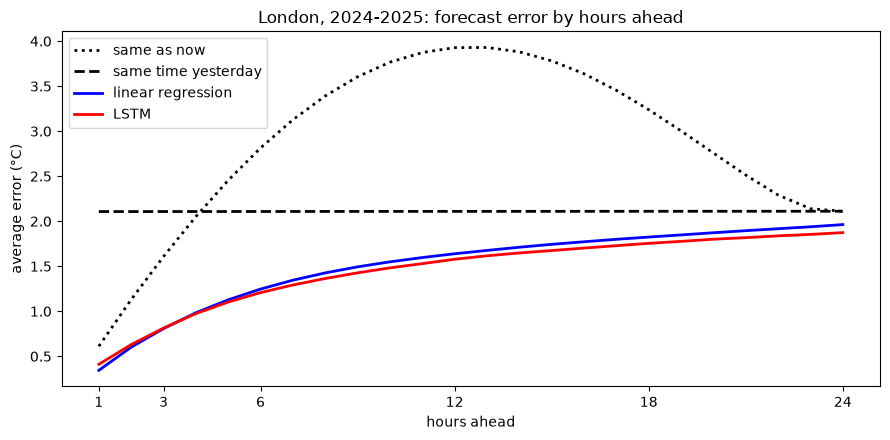

LSTM better than linear regression by (°C): 1 h: -0.07, 3 h: -0.01, 6 h: +0.04, 12 h: +0.06, 24 h: +0.09
24 h ahead, compared with "same time yesterday": linear regression 0.15 °C better, LSTM 0.24 °C better


In [ ]:
table = pd.DataFrame(errors, index=hours).T
display(table[[1, 3, 6, 12, 24]].round(2).rename(columns=lambda h: f'{h} h ahead'))

plt.figure(figsize=(9, 4.5))
for name, style in zip(table.index, ['k:', 'k--', 'b-', 'r-']):
    plt.plot(hours, table.loc[name], style, lw=2, label=name)
plt.xlabel('hours ahead'); plt.ylabel('average error (°C)'); plt.xticks([1, 3, 6, 12, 18, 24])
plt.title('London, 2024-2025: forecast error by hours ahead'); plt.legend(); plt.tight_layout(); plt.show()

gain = (table.loc['linear regression'] - table.loc['LSTM']).round(2)
print('LSTM better than linear regression by (°C):', ', '.join(f'{h} h: {gain[h]:+.2f}' for h in (1, 3, 6, 12, 24)))
print(f'24 h ahead, compared with "same time yesterday": linear regression {table.loc["same time yesterday", 24] - table.loc["linear regression", 24]:.2f} °C better, '
      f'LSTM {table.loc["same time yesterday", 24] - table.loc["LSTM", 24]:.2f} °C better')

- **How far ahead matters more than which model.** One hour ahead, every model except "same time yesterday" is within about half a degree. A day ahead, the best is still off by almost 2 °C on average.
- **"Same as now"** is good for 1 hour (0.61 °C) and poor at 12 hours (3.93 °C), because temperature swings between day and night. It recovers at 24 hours (2.11 °C) because this time tomorrow is a lot like now.
- **"Same time yesterday"** is 2.11 °C at every horizon: a tough benchmark a day ahead.
- **Linear regression is best at short range** (0.34 °C one hour ahead) and close to the LSTM everywhere.
- **The LSTM only wins from about 6 hours out, and only slightly:** 0.04 °C better than linear regression at 6 hours, 0.06 at 12 and 0.09 at 24. It took about 4.5 minutes to train against 0.2 seconds, and was still improving slowly after 30 epochs.
- **A day ahead, neither beats "same time yesterday" by much:** linear regression by 0.15 °C (about 7%) and the LSTM by 0.24 °C (about 11%).

### 2. What the forecasts look like
A week from the test period: what actually happened, against each model's forecast made 24 hours earlier.

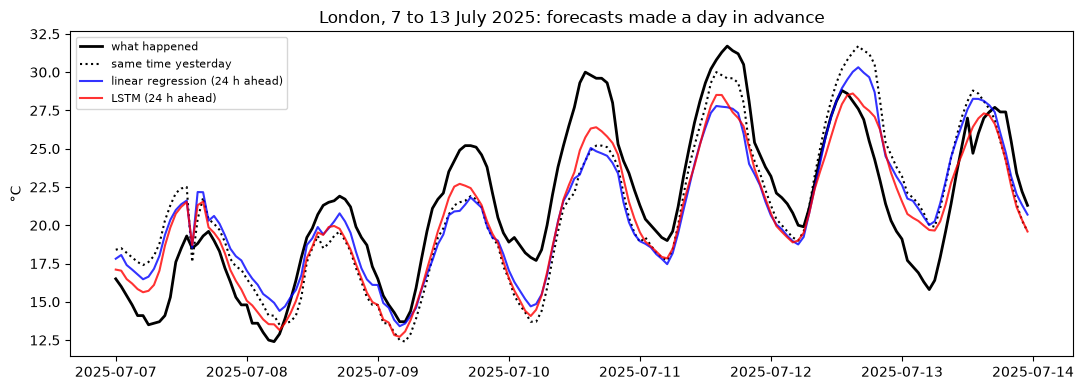

In [ ]:
start = london.index[london.time_utc == '2025-07-07 00:00:00'][0]           # Monday 7 July 2025 (UTC), a week from the test years
idx = np.arange(start, start + 7 * 24)                                          # the hours to plot
w = idx - PAST - AHEAD + 1                                                      # window whose 24th hour ahead is that hour
lr_24 = linreg.predict(windows[w].reshape(len(w), -1))[:, -1]
lstm_24 = lstm.predict(windows[w], verbose=0)[:, -1]
plt.figure(figsize=(11, 4))
plt.plot(london.time_utc[idx], temp[idx], 'k-', lw=2, label='what happened')
plt.plot(london.time_utc[idx], temp[idx - 24], 'k:', label='same time yesterday')
plt.plot(london.time_utc[idx], lr_24, 'b-', alpha=0.8, label='linear regression (24 h ahead)')
plt.plot(london.time_utc[idx], lstm_24, 'r-', alpha=0.8, label='LSTM (24 h ahead)')
plt.ylabel('°C'); plt.title('London, 7 to 13 July 2025: forecasts made a day in advance'); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Verdict
**For forecasting London's temperature from its own past, the LSTM is not worth it at short range and only marginally worth it a day ahead.** Linear regression is best for the next hour or two. The LSTM edges ahead from about 6 hours out, by less than a tenth of a degree, at well over a thousand times the training time. And a day ahead, both are only 0.15 to 0.24 °C better than simply copying yesterday.

**Why the ceiling is low:** the last 72 hours in one place don't contain what decides tomorrow's weather, which is the weather arriving from elsewhere. That is why real forecasts are built from observations over a wide area and models of the atmosphere, not from one location's history.

**Caveats:** modelled grid-cell data rather than a weather station; one time split (testing on 2024-2025); the LSTM was still improving slowly at 30 epochs; no time-of-day or season inputs; and an average error treats every miss alike, while a heating or energy business might care most about cold snaps.

**Next:** my next test would be adding hour-of-day and day-of-year as inputs, and temperatures from places upwind of London, before trying a bigger network.